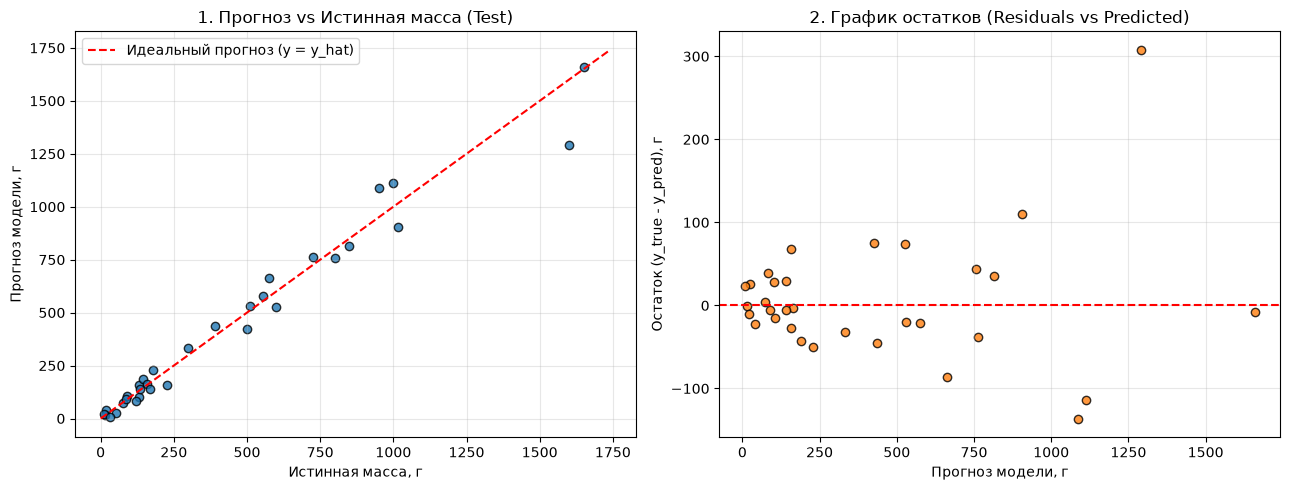

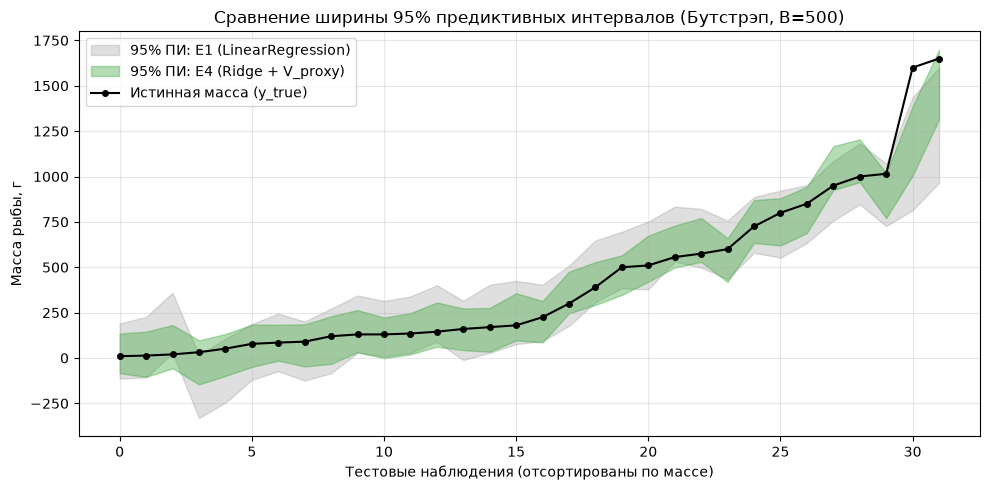

In [1]:
import os
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline

# Безопасный переход в корень проекта
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.evaluate import get_frozen_split, load_dataset  # type: ignore
from src.features import VolumeAdder  # type: ignore
from src.train import build_preprocessor  # type: ignore
from src.bootstrap import bootstrap_intervals  # type: ignore

os.makedirs("reports/figures", exist_ok=True)

df = load_dataset()
X_train, X_test, y_train, y_test = get_frozen_split(df)
model = joblib.load("models/best_model.joblib")

preds = model.predict(X_test)
residuals = y_test.values - preds

# 1. График: Прогноз vs Истинное значение и Остатки vs Прогноз
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, preds, alpha=0.8, color="#1f77b4", edgecolors="k")
lims = [0, max(y_test.max(), preds.max()) * 1.05]
axes[0].plot(lims, lims, "r--", label="Идеальный прогноз (y = y_hat)")
axes[0].set_title("1. Прогноз vs Истинная масса (Test)")
axes[0].set_xlabel("Истинная масса, г")
axes[0].set_ylabel("Прогноз модели, г")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(preds, residuals, alpha=0.8, color="#ff7f0e", edgecolors="k")
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("2. График остатков (Residuals vs Predicted)")
axes[1].set_xlabel("Прогноз модели, г")
axes[1].set_ylabel("Остаток (y_true - y_pred), г")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("reports/figures/lab02_residuals.png", dpi=150)
plt.show()

# 2. График сравнения 95% предиктивных интервалов E1 vs E4 (бутстрэп)
num_cols = ["Length1", "Length2", "Length3", "Height", "Width"]
cat_cols = ["Species"]

pipe_e1 = Pipeline([("preprocess", build_preprocessor(num_cols, cat_cols)), ("regressor", LinearRegression())])
pipe_e4 = Pipeline([("add_volume", VolumeAdder()), ("preprocess", build_preprocessor(num_cols + ["V_proxy"], cat_cols)), ("regressor", Ridge(alpha=1.0))])

res_e1 = bootstrap_intervals(pipe_e1, X_train, y_train, X_test)
res_e4 = bootstrap_intervals(pipe_e4, X_train, y_train, X_test)

order = np.argsort(y_test.values)
y_sorted = y_test.values[order]

plt.figure(figsize=(10, 5))
plt.fill_between(range(len(y_sorted)), res_e1["pi_low"].values[order], res_e1["pi_high"].values[order],
                 color="gray", alpha=0.25, label="95% ПИ: E1 (LinearRegression)")
plt.fill_between(range(len(y_sorted)), res_e4["pi_low"].values[order], res_e4["pi_high"].values[order],
                 color="#2ca02c", alpha=0.35, label="95% ПИ: E4 (Ridge + V_proxy)")
plt.plot(range(len(y_sorted)), y_sorted, "ko-", markersize=4, label="Истинная масса (y_true)")
plt.title("Сравнение ширины 95% предиктивных интервалов (Бутстрэп, B=500)")
plt.xlabel("Тестовые наблюдения (отсортированы по массе)")
plt.ylabel("Масса рыбы, г")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("reports/figures/lab02_bootstrap_ci.png", dpi=150)
plt.show()

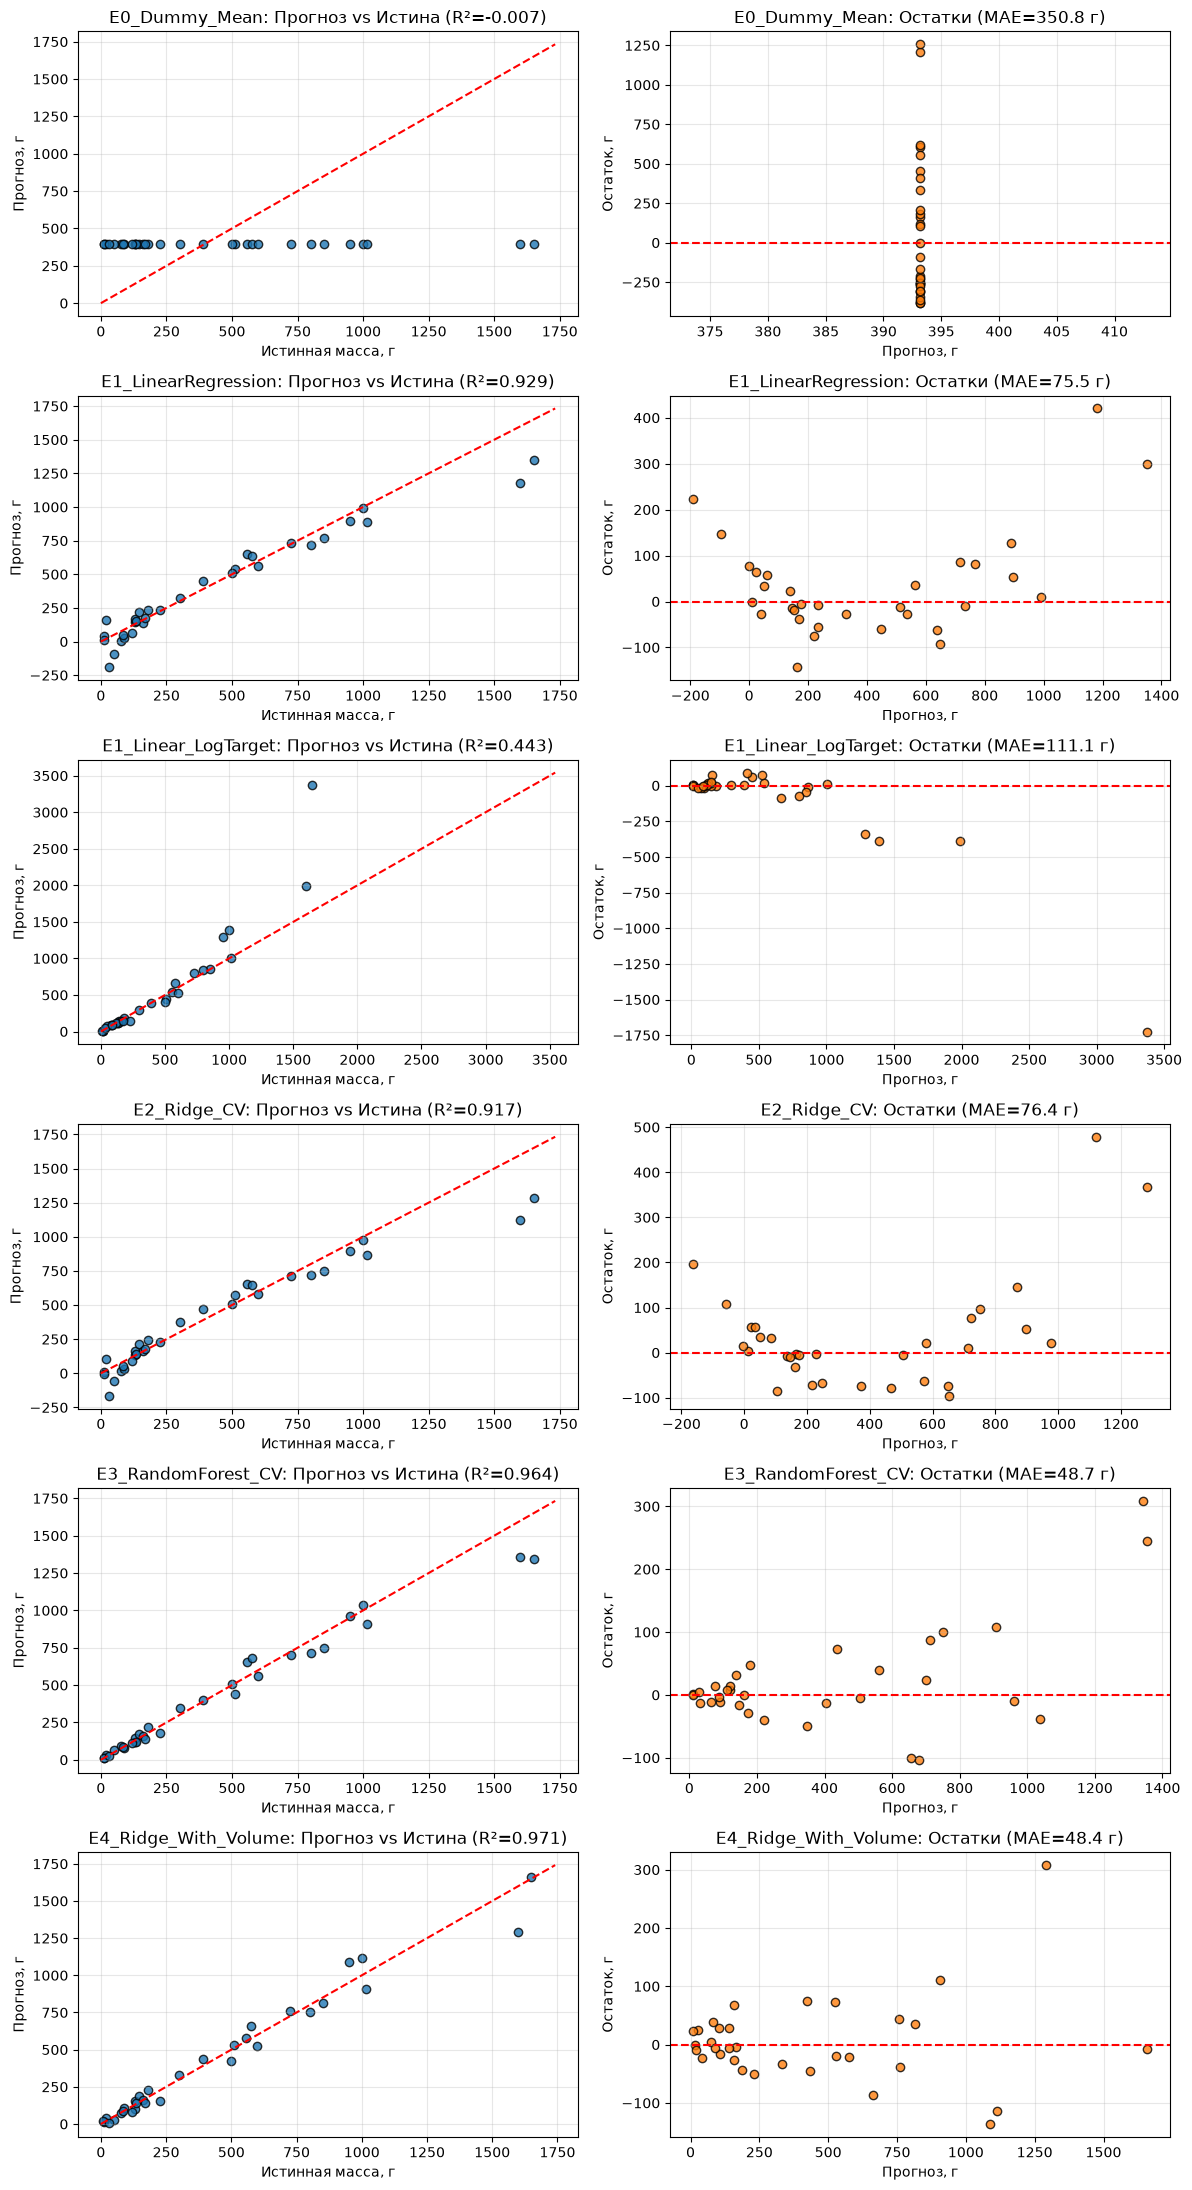

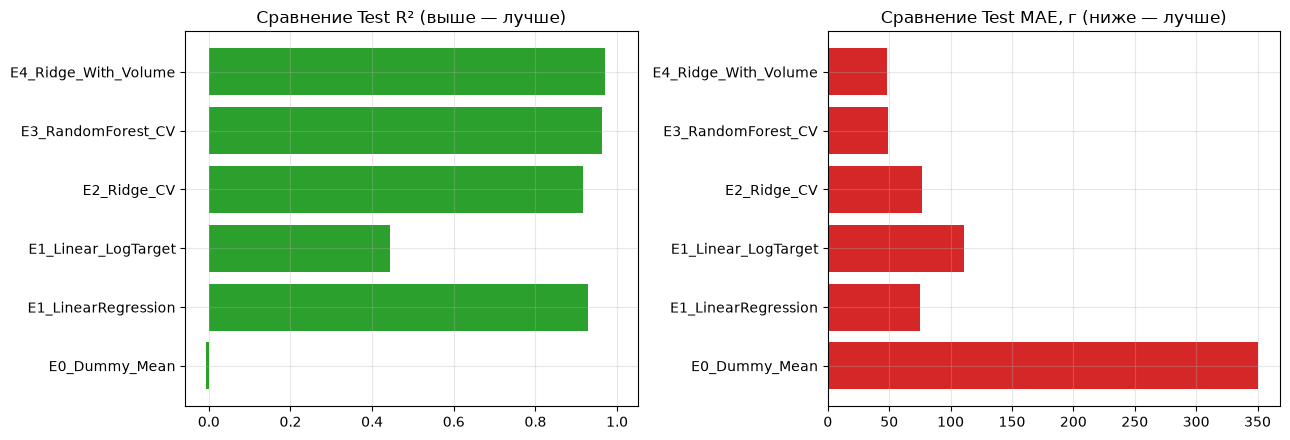

In [2]:
import os
import sys
import tempfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline

# Безопасный переход в корень проекта
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.evaluate import get_frozen_split, load_dataset  # type: ignore
from src.train import build_preprocessor  # type: ignore

os.makedirs("reports/figures", exist_ok=True)

df = load_dataset()
X_train, X_test, y_train, y_test = get_frozen_split(df)
model = joblib.load("models/best_model.joblib")

num_cols = ["Length1", "Length2", "Length3", "Height", "Width"]
cat_cols = ["Species"]
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models_to_compare = {
    "E0_Dummy_Mean": Pipeline([
        ("preprocess", build_preprocessor(num_cols, cat_cols)),
        ("regressor", DummyRegressor(strategy="mean")),
    ]),
    "E1_LinearRegression": Pipeline([
        ("preprocess", build_preprocessor(num_cols, cat_cols)),
        ("regressor", LinearRegression()),
    ]),
    "E1_Linear_LogTarget": Pipeline([
        ("preprocess", build_preprocessor(num_cols, cat_cols)),
        ("regressor", TransformedTargetRegressor(
            regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1
        )),
    ]),
    "E2_Ridge_CV": GridSearchCV(
        Pipeline([("preprocess", build_preprocessor(num_cols, cat_cols)), ("regressor", Ridge())]),
        param_grid={"regressor__alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]},
        cv=cv, scoring="neg_mean_squared_error",
    ),
    "E3_RandomForest_CV": GridSearchCV(
        Pipeline([("preprocess", build_preprocessor(num_cols, cat_cols)), ("regressor", RandomForestRegressor(random_state=42))]),
        param_grid={"regressor__n_estimators": [100, 200], "regressor__max_depth": [None, 6, 10], "regressor__min_samples_leaf": [1, 2]},
        cv=cv, scoring="neg_mean_squared_error",
    ),
    "E4_Ridge_With_Volume": model,
}

# 1. Сетка графиков для ВСЕХ моделей (6x2)
fig, axes = plt.subplots(len(models_to_compare), 2, figsize=(12, 22))
metrics_summary = []

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()
exp = client.get_experiment_by_name("FishGrow_Regression")
runs_by_name = {}
if exp is not None:
    for r in client.search_runs(experiment_ids=[exp.experiment_id]):
        runs_by_name[r.info.run_name] = r.info.run_id

for idx, (name, est) in enumerate(models_to_compare.items()):
    if name != "E4_Ridge_With_Volume":
        est.fit(X_train, y_train)
    y_hat = est.predict(X_test)
    res = y_test.values - y_hat
    r2 = r2_score(y_test, y_hat)
    mae = mean_absolute_error(y_test, y_hat)
    metrics_summary.append({"Model": name, "Test_R2": r2, "Test_MAE": mae})

    # Левый график: Прогноз vs Истина
    ax_l = axes[idx, 0]
    ax_l.scatter(y_test, y_hat, alpha=0.8, color="#1f77b4", edgecolors="k")
    max_val = max(y_test.max(), y_hat.max()) * 1.05
    ax_l.plot([0, max_val], [0, max_val], "r--")
    ax_l.set_title(f"{name}: Прогноз vs Истина (R²={r2:.3f})")
    ax_l.set_xlabel("Истинная масса, г")
    ax_l.set_ylabel("Прогноз, г")
    ax_l.grid(True, alpha=0.3)

    # Правый график: Остатки
    ax_r = axes[idx, 1]
    ax_r.scatter(y_hat, res, alpha=0.8, color="#ff7f0e", edgecolors="k")
    ax_r.axhline(0, color="r", linestyle="--")
    ax_r.set_title(f"{name}: Остатки (MAE={mae:.1f} г)")
    ax_r.set_xlabel("Прогноз, г")
    ax_r.set_ylabel("Остаток, г")
    ax_r.grid(True, alpha=0.3)

    # Прикрепляем индивидуальный график в соответствующий запуск MLflow
    if name in runs_by_name:
        with tempfile.TemporaryDirectory() as tmpdir:
            single_fig, single_ax = plt.subplots(1, 2, figsize=(10, 4))
            single_ax[0].scatter(y_test, y_hat, alpha=0.8, edgecolors="k")
            single_ax[0].plot([0, max_val], [0, max_val], "r--")
            single_ax[0].set_title(f"{name}: Predicted vs Actual")
            single_ax[1].scatter(y_hat, res, alpha=0.8, color="orange", edgecolors="k")
            single_ax[1].axhline(0, color="r", linestyle="--")
            single_ax[1].set_title(f"{name}: Residuals")
            plt.tight_layout()
            plot_path = os.path.join(tmpdir, f"{name}_plots.png")
            single_fig.savefig(plot_path, dpi=120)
            plt.close(single_fig)
            client.log_artifact(runs_by_name[name], plot_path, artifact_path="plots")

plt.tight_layout()
plt.savefig("reports/figures/lab02_all_models_comparison.png", dpi=150)
plt.show()

# 2. Столбчатая диаграмма сравнения R2 и MAE всех моделей
sum_df = pd.DataFrame(metrics_summary)
fig2, ax2 = plt.subplots(1, 2, figsize=(13, 4.5))

ax2[0].barh(sum_df["Model"], sum_df["Test_R2"], color="#2ca02c")
ax2[0].set_title("Сравнение Test R² (выше — лучше)")
ax2[0].set_xlim(min(0, sum_df["Test_R2"].min() - 0.05), 1.05)
ax2[0].grid(True, alpha=0.3)

ax2[1].barh(sum_df["Model"], sum_df["Test_MAE"], color="#d62728")
ax2[1].set_title("Сравнение Test MAE, г (ниже — лучше)")
ax2[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("reports/figures/lab02_metrics_comparison.png", dpi=150)
plt.show()